In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [42]:
df = pd.read_csv("Military_Funding_Table.csv")

In [43]:
years = df["Year"]
fmf = df["Foreign Military Financing"]
usai = df["Ukraine Security Assitance Initiative"]
pda = df["Presidential Drawdown Authority"]
total = df["Total"]

In [44]:
sns.set_theme(style = "whitegrid", context = "notebook")

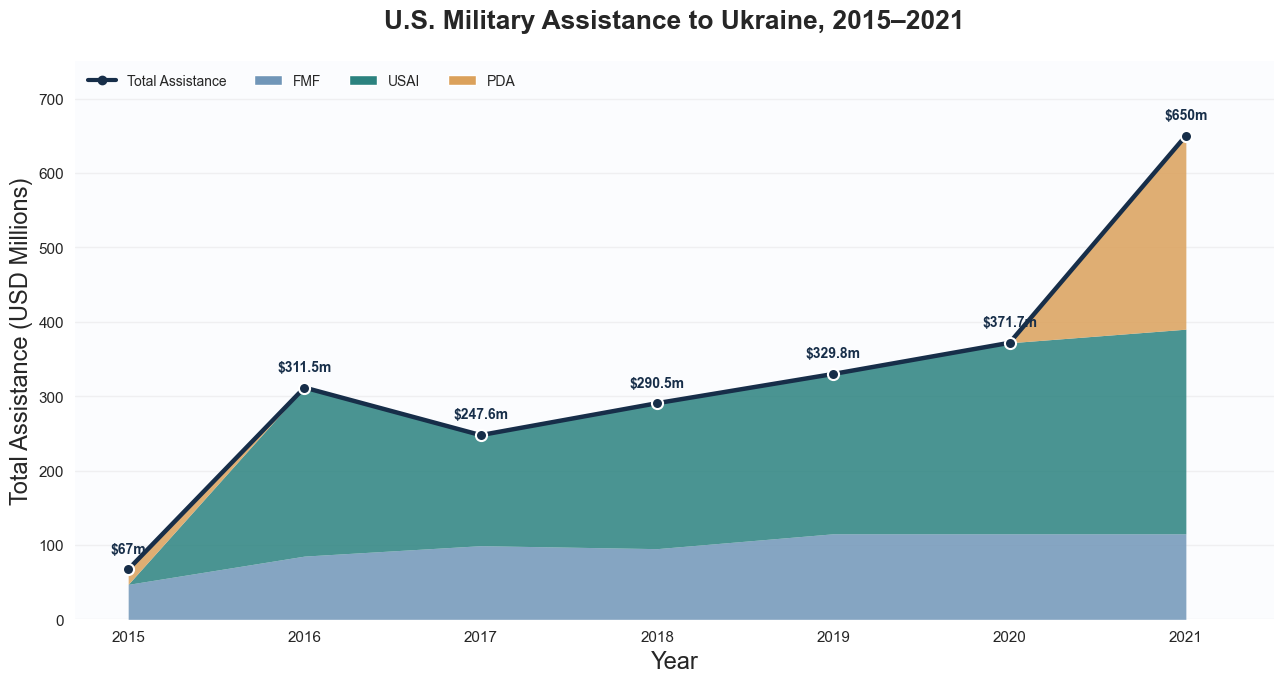

In [53]:
colors = {
    "FMF": "#7196B8",
    "USAI": "#2B827F",
    "PDA": "#DBA15B",
    "Total": "#172E49"} 

fig, ax = plt.subplots(figsize = (13, 7))
fig.patch.set_facecolor("white")
ax.set_facecolor("#FBFCFE")

ax.stackplot(years, fmf, usai, pda,
    colors=[
        colors["FMF"],
        colors["USAI"],
        colors["PDA"]],
    alpha = 0.85,
    linewidth = 0)

sns.lineplot(
    x = years,
    y = total,
    color = colors["Total"],
    linewidth = 3.2,
    marker = "o",
    markersize = 8,
    markeredgecolor = "white",
    markeredgewidth = 1.5,
    errorbar = None,
    ax = ax,
    zorder = 5)

for year, value in zip(years, total):
    ax.annotate(
        f"${value:,.1f}m" if value % 1 else f"${value:,.0f}m",
        (year, value),
        xytext = (0, 12),
        textcoords = "offset points",
        ha = "center",
        fontsize = 10,
        fontweight = "bold",
        color = colors["Total"])

legend_elements = [
    Line2D([0], [0], color = colors["Total"],
           lw = 3, marker = "o", label = "Total Assistance"),
    Patch(facecolor = colors["FMF"], label = "FMF"),
    Patch(facecolor = colors["USAI"], label = "USAI"),
    Patch(facecolor = colors["PDA"], label = "PDA")]

ax.legend(
    handles = legend_elements,
    loc = "upper left",
    frameon = False,
    ncol = 4,
    fontsize = 10)

ax.set_title("U.S. Military Assistance to Ukraine, 2015–2021",
    fontsize = 19,
    fontweight = "bold",
    pad = 24,
    loc = "center")

ax.set_xlabel("Year", fontsize = 17)
ax.set_ylabel("Total Assistance (USD Millions)", fontsize = 17)

ax.set_xticks(years)
ax.set_xlim(2014.7, 2021.5)
ax.set_ylim(0, 750)

ax.grid(axis="y", alpha = 0.25)
ax.grid(axis="x", visible = False)
ax.set_axisbelow(True)

sns.despine(left = True, bottom = True)
ax.tick_params(axis = "both", length = 0, pad = 8)

plt.tight_layout()

plt.savefig(
    "Ukraine_Military_Assistance.png",
    dpi = 300,
    bbox_inches = "tight")

plt.show()